# <span style="color:green"> Numerical Simulation Laboratory (NSL) </span>
## <span style="color:blue">  Numerical exercises 4</span>

### Exercise 04.1

In Statistical Mechanics the Maxwell–Boltzmann distribution (<a href="https://en.wikipedia.org/wiki/Maxwell%E2%80%93Boltzmann_distribution" target="_blank">Link Wikipedia</a>) is a probability distribution used for describing particle speeds in idealized gases. However, rarefied gases at ordinary temperatures behave very nearly like an ideal gas and the Maxwell–Boltzmann speed distribution is an excellent approximation for such gases. For a 3D system its formula is:
$$p(v,T) = \left( \frac{m}{2\pi k_B T} \right)^{3/2} 4\pi v^2 e^{-\frac{m v^2}{2 k_B T}}$$

By using LJ reduced units (Lenght: $\sigma$; Energy: $\epsilon$; Mass: the mass, $m$, of the particles; Temperature: $\epsilon/k_B$; velocity: $\sqrt{\epsilon/m}$) its form becomes:
$$p(v^*,T^*) = \frac{1}{(2\pi T^*)^{3/2}} 4\pi (v^*)^2 e^{-\frac{(v^*)^2}{2 T^*}}$$

The NSL_SIMULATOR code already computes the total (internal) energy per particle, $E/N$, the potential energy per particle, $U/N$, the kinetic energy per particle, $K/N$, the temperature, $T$, and the pressure, $P$.

**Include the calculation of the Maxwell–Boltzmann distribution, $p(v^*,T^*)$, inside your Molecular Dynamics code by using data blocking to obtain single block averages, progressive average values and progressive uncertainties for $p(v^*,T^*)$.**

Remember that, the Maxwell–Boltzmann distribution, $p(v^*,T^*)$, can be approximately computed as a **normalized histogram** on an appropriate interval $\left[ 0, v_{max}\right]$ and chosing the number of bins into which you want to divide this interval.

### Exercise 04.2

By means of your upgraded code, <span style="color:red">perform MD simulations via a Lennard-Jones model</span> ( e.g. Argon parameters: $\sigma = 0.34$ nm, $\epsilon/k_B = 120$ K, $m=39.948$ amu) in the following conditions:
- gas phase: $\rho^\star = 0.05$, $T^\star \sim  2.0$ (cut-off radius: $r_c = 5.0$)

starting from a <span style="color:red">**very low entropic** initial configuration</span>:
1. initial **particle positions**: <span style="color:red">fcc crystal occupying half of the simulation box in each dimension</span>
2. initial **velocity distribution**: **$p_\delta(v^*,T^*) = \delta\left( v^* - v_{T^*}\right)$** where $v_{T^*}$ is suitably connected to $T^*$. For example, this condition could be obtained by imposing that every particle has an initial velocity $\pm v_{T^*}$ for **only one** of its velocity components: $v_x$, $v_y$, $v_z$.

The goal is to show that, by evolving such initial condition via a Molecular Dynamics simulation, the velocity distribution tends to approximate the Maxwell–Boltzmann distribution.

- **Produce some pictures that show this convergence**
- The evolution of the system moves towards the increasing of entropy (more homeogeneous configuration of particles)? What would you find by changing the direction of time? Comment on these aspects in your jupyter-notebook

**Note that** the MD simulation will conserve the total energy; thus the kinetic energy and the temperature are not constant of motion ... the comparison should be done with $p(v^*,T^*_{\rm eff})$ where $T^*_{\rm eff}$ is the effective temperature obtained once the system has been equilibrated.

### Exercise 04.3

Starting from the **final states** of two MD simulations of the system in Exercise 04.2, one with about $5\times 10^3$ time-steps the other with about $5\times 10^4$ time-steps, by changing the direction of time (e.g. by inverting the final velocities, i.e. ... ), try to return back to the very low entropic initial configuration of Exercise 04.2. Is this possible? (for example, one can monitor the behavior of the average **potential energy** and the average **temperature** in **each block** as a function of time going **in both directions**. Show some picture and comment on what you find in your jupyter-notebook.

# <span style="color:green"> RESULTS: </span>

In this notebook we will analyze the statistical properties of a rarefied gas of Argon atoms, simulated with molecular dynamics (MD) using the Verlet algorithm. In this simulation the atoms interact with each other through the Lennard-Jones (LJ) potential:
$$V(r) = 4\epsilon\left[\left(\frac{\sigma}{r}\right)^{12} - \left(\frac{\sigma}{r}\right)^{6}\right]$$
and all quantities are expressed in reduced LJ units, with the Argon parameters being: $\sigma = 0.34$ nm, $\epsilon/k_B = 120$ K and $m = 39.948$ amu. In these units $r^* = r/\sigma$, $T^* = k_B T/\epsilon$ and $v^* = v\sqrt{m/\epsilon}$. From now on the asterisks are dropped when the units are clear.

#### The Verlet algorithm
The Verlet method is a deterministic numerical integration scheme for Newton's equations of motion. It uses the positions at the two previous time steps and the forces $\vec F(t)$ acting on the particles, derived from the potential, to compute the positions at the next time step; the velocities are then obtained from the positions. Expanding $\vec r(t\pm\Delta t)$ in a Taylor series around $t$ up to the third order:
$$\vec r(t\pm\Delta t) = \vec r(t) \pm \vec v(t)\,\Delta t + \frac{\vec F(t)}{2m}\,\Delta t^2 \pm \frac{1}{6}\,\vec r^{\,(3)}(t)\,\Delta t^3 + O(\Delta t^4)$$
Summing the two expansions, the odd terms cancel and we get the position at the next step as a function of the two previous ones:
$$\vec r(t+\Delta t) = 2\vec r(t) - \vec r(t-\Delta t) + \frac{\vec F(t)}{m}\,\Delta t^2 + O(\Delta t^4)$$
while their difference gives the velocity:
$$\vec v(t) = \frac{\vec r(t+\Delta t) - \vec r(t-\Delta t)}{2\Delta t} + O(\Delta t^2)$$
Since the update formula is symmetric under $\Delta t\to-\Delta t$, the algorithm is time-reversible. The total energy is not conserved exactly because of the finite time step, but it only shows small bounded fluctuations and no systematic drift over long runs, which makes the algorithm well suited for MD simulations.

## Exercise 4.1
The first statistical property we analyze is the velocity distribution of the particles. For a classical system in thermal equilibrium, in particular for a rarefied gas, the speeds follow the Maxwell-Boltzmann distribution, which in LJ units can be written as:
$$p(v^*,T^*) = \frac{4\pi (v^*)^2}{(2\pi T^*)^{3/2}}\, e^{-\frac{(v^*)^2}{2 T^*}}$$

In the simulation this distribution is estimated as a normalized histogram of the speeds $|\vec v_i|$ of the $N$ particles on the interval $[0, v_{max}]$. In the vector  <small><code>_measurement</code></small> a section of  <small><code>_n_bins_v</code></small> elements is reserved for the bin counts, and the bin width is $\Delta v = v_{max}/n_{bins}$. The upper limit is chosen as the mean speed plus five standard deviations of the speed distribution, which for the Maxwell-Boltzmann distribution are:
$$\langle v\rangle = \sqrt{\frac{8T^*}{\pi}}, \qquad \sigma_v = \sqrt{T^*\left(3-\frac{8}{\pi}\right)} \quad\Rightarrow\quad v_{max} = \sqrt{\frac{8T^*}{\pi}} + 5\sqrt{T^*\left(3-\frac{8}{\pi}\right)}$$
so that only a negligible fraction of the particles falls beyond $v_{max}$. This is the implementation in <small><code>initialize_properties()</code></small>:
<small>
```cpp
double v_max = sqrt(8.0*_temp/M_PI) + 5.0*sqrt(_temp * (3.0 - 8.0/M_PI));
_bin_size_v = v_max/(double)_n_bins_v;
```
</small>

At every step of the evolution of the system each particle adds one count to the bin corresponding to its speed. The counting is done in  <small><code>measure()</code></small>:
<small>
```cpp
for(int i=0; i<_npart; i++){
    double v_mod = norm(_particle(i).getvelocity());
    int bin = int(v_mod/_bin_size_v);
    if (bin < _n_bins_v) _measurement(_index_pofv + bin)++;
}
```
</small>

At the end of each block of the data blocking method the counts are averaged over the steps of the block and normalized by dividing them by $N\,\Delta v$, so that the histogram becomes a probability density. The block averages are accumulated to obtain the progressive mean and its statistical error. For each bin the output file stores the speed at the bin centre, $(i+\tfrac12)\Delta v$, the block average, the progressive mean and the progressive error:
<small>
```cpp
double norm = 1.0 / (double(_npart) * _bin_size_v);
coutf << "#BLOCK: " << blk << endl;
for (int i=0; i < _n_bins_v; i++){
    int index = _index_pofv + i;
    double bin_ave  = _global_av(index);
    double bin_ave2 = _global_av2(index);
    // v | block average | progressive mean | progressive error
    coutf << setw(12) << (i + 0.5) * _bin_size_v
          << setw(12) << _average(index) * norm
          << setw(12) << bin_ave / double(blk) * norm
          << setw(12) << this->error(bin_ave, bin_ave2, blk) * norm << endl;
}
```
</small>

## Exercise 4.2

In this exercise we checked whether the system relaxes to the Maxwell-Boltzmann distribution starting from a configuration far from the equilibrium. The particles are initially placed in one half of the simulation box, leaving the other half empty, and their speeds are drawn from a delta distribution centred in $v_T=\sqrt{3T_0^*}$, where $v_T$ follows from equipartition ($\langle v^2\rangle=3T^*$ in LJ units). To realize this distribution each particle is given a velocity of modulus $v_T$ along a randomly chosen axis, with a random sign, as shown in the code below:
<small>
```cpp
double v_T = sqrt(3.0*_temp);
for(int i=0; i<_npart; i++){
    int dir = int(_rnd.Rannyu()*3);                           // random axis
    double sign = (_rnd.Rannyu() < 0.5) ? 1.0 : -1.0;         // random sign
    for(int d=0; d<_ndim; d++) _particle(i).setvelocity(d, (d==dir) ? v_T*sign : 0.0);
}
```
</small>

The system then evolved in the microcanonical ensemble (NVE) and we followed it during its equilibration. The collisions redistribute the kinetic energy among the particles, so the delta spreads, while the gas expands until it fills the whole box. We expect $p(v,t)$ to tend to the Maxwell-Boltzmann distribution, since this is the equilibrium velocity distribution of the system.

The total energy is conserved, so the final temperature is set by $E=K+U$ and not by $T_0^*$, because part of the kinetic energy is transferred to the potential one while the particles spread. We therefore estimate the temperature of each snapshot from the histogram, $T^*_{eff}=\langle v^2\rangle/3$, and compare the final distribution with the Maxwell-Boltzmann one at $T^*_{eff}$.

To follow the evolution of the delta distribution the blocks must be short: each block contains 100 simulation steps, and to draw the histogram we use the block average column of the output file, which is $p(v)$ in that time window. Using the progressive mean would mix the transient with the equilibrium.

The simulation was run with $N=108$ particles and a density of $\rho^*=0.05$, giving the box side as $L=(N/\rho^*)^{1/3}\simeq12.9$; the initial temperature was set to $T_0^*=2$, the cut-off radius to $r_{cut}=5$ and the time step to $\Delta t^*=0.001$, for 50 blocks of 50 steps each. The plot below shows the evolution of $p(v,t)$ towards the Maxwell-Boltzmann distribution.

In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt

In [2]:
def load_all_blocks(filename):
    n_blocks = sum(l.startswith("#BLOCK:") for l in open(filename))
    d = np.loadtxt(filename)
    return dict(enumerate(d.reshape(n_blocks, -1, d.shape[1]), start=1))

T_eff = 1.704


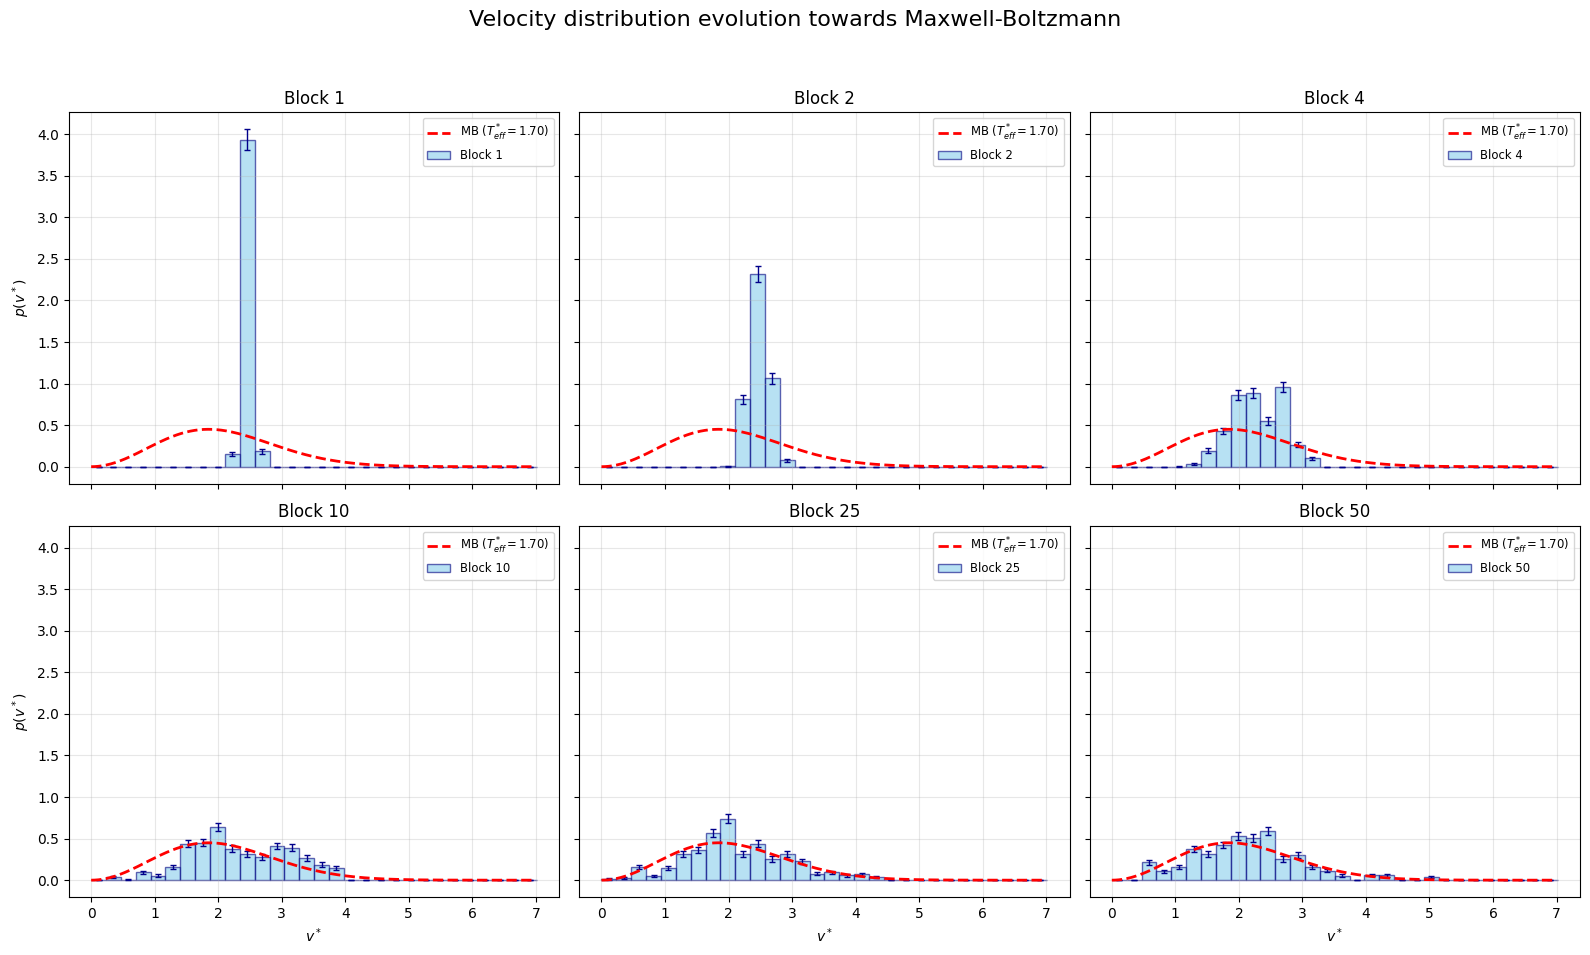

In [ ]:
pofv_path = 'OUTPUT_final/pofv.dat'
temp_path = 'OUTPUT_final/temperature.dat'  # for T_eff
target_blocks = [1, 2, 4, 10, 25, 50]
npart, nsteps = 108, 10 

# Average of the instantaneous block temperature over the equilibrated part of the simulation.
T_all = np.loadtxt(temp_path)[:, 1]      
T_eff = T_all[int(0.8 * len(T_all)):].mean()
print(f"T_eff = {T_eff:.3f}")

blocks = load_all_blocks(pofv_path)     

# Maxwell-Boltzmann speed distribution in LJ units (m = k_B = 1) at T_eff
v_fine = np.linspace(0, 7, 500)
mb = 4 * np.pi * v_fine**2 * (2 * np.pi * T_eff)**-1.5 * np.exp(-v_fine**2 / (2 * T_eff))

fig, axs = plt.subplots(2, 3, figsize=(16, 10), sharex=True, sharey=True)
fig.suptitle(r'Velocity distribution evolution towards Maxwell-Boltzmann', fontsize=16)

for ax, b in zip(axs.flatten(), target_blocks):
    if b not in blocks:
        ax.text(0.5, 0.5, f'Block {b}\nnot found', ha='center', va='center', color='red')
        continue
    v, p_block = blocks[b][:, 0], blocks[b][:, 1]   # column 1 = p(v) of this single block
    dv = v[1] - v[0]                                # bin width

    # Poisson error: C_i = total counts in bin i over the block, p_i = C_i / (npart * dv * nsteps)
    counts = p_block * npart * dv * nsteps
    err = np.sqrt(counts) / (npart * dv * nsteps)

    ax.bar(v, p_block, width=dv, color='skyblue', edgecolor='navy', alpha=0.6, label=f'Block {b}')
    ax.errorbar(v, p_block, yerr=err, fmt='none', ecolor='darkblue', capsize=2, elinewidth=1)
    ax.plot(v_fine, mb, 'r--', lw=2, label=rf'MB ($T^*_{{eff}}={T_eff:.2f}$)')

    ax.set_title(f'Block {b}')
    ax.grid(alpha=0.3)
    ax.legend(fontsize='small', loc='upper right')

for ax in axs[1]:  ax.set_xlabel(r'$v^*$')
for ax in axs[:, 0]: ax.set_ylabel(r'$p(v^*)$')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

At the beginning $p(v)$ is mostly a single peak at $v_T=\sqrt{6}\simeq2.45$. After about 4 blocks the peak broadens, and by 10 blocks the distribution is well fitted by the Maxwell-Boltzmann one at $T^*_{eff}=1.7$ as expected.

## Exercise 4.3

In this final exercise we study the time reversibility of the Verlet integration method, for runs of different lengths. In particular, we want to verify whether the system can return to the low-entropy state from which it started once its time evolution is reversed.

The Verlet algorithm is symmetric under $\Delta t\to-\Delta t$:
$$\vec r(t+\Delta t) = 2\vec r(t) - \vec r(t-\Delta t) + \frac{\vec F(t)}{m}\,\Delta t^2$$
The time inversion is therefore obtained by simply exchanging the current and the previous positions. After the exchange, the next step computes $\vec r(t-2\Delta t)$ from $\vec r(t-\Delta t)$ and $\vec r(t)$. The velocities, estimated as $[\vec r(t+\Delta t)-\vec r(t-\Delta t)]/2\Delta t$, change sign automatically. To implement it we added this block to the Verlet implementation:
<small>
```cpp
if(time_inversion){
    for(int i=0; i<_npart; i++) for(int d=0; d<_ndim; d++){
        double appo = _particle(i).getposition(d, true);                  // current position
        _particle(i).setposition(d, _particle(i).getposition(d, false));  // current <- old
        _particle(i).setpositold(d, appo);                                // old <- current
    }
}
```
</small>

Both simulations start from the low-entropy configuration, with all the particles in one half of the box. Each run lasts twice the number of steps indicated in the plots, and the time inversion is applied once, exactly at half of the run. The system then evolves backward for as many steps as the forward evolution.

In perfectly reversible dynamics the system would retrace its trajectory and return to the initial configuration. In practice, the finite precision of floating-point arithmetic introduces round-off errors ($\sim10^{-16}$). Moreover the dynamics of the gas is chaotic: two trajectories that start almost identically can move apart exponentially fast, so even a tiny initial difference becomes large after a while. The round-off errors therefore grow exponentially in time, until they completely change the trajectory. We thus expect the return to the initial state to work only for short runs (where the errors have not had time to grow) and to be lost for long ones (where the system has reached thermal equilibrium). In other words, the microscopic dynamics is reversible, but returning to a low-entropy state requires reversing all the velocities exactly, and this is unstable against any perturbation.

The plots below show, block by block, the potential energy per particle and the temperature. The red dashed line marks the inversion. The black dashed line is the second half of the run mirrored with respect to the inversion point: if the evolution is perfectly reversible, it overlaps the first half.

In [4]:
# Run length -> output folder (rows of the figure)
runs = {r'$5\times 10^3$': './OUTPUT_5e3', r'$5\times 10^4$': './OUTPUT_5e4'}
# File, y-label, name, color (columns of the figure)
props = [('potential_energy.dat', r'$U/N$', 'Potential energy', '#0c459a'),
         ('temperature.dat',      r'$T$',   'Temperature',      '#109e28')]

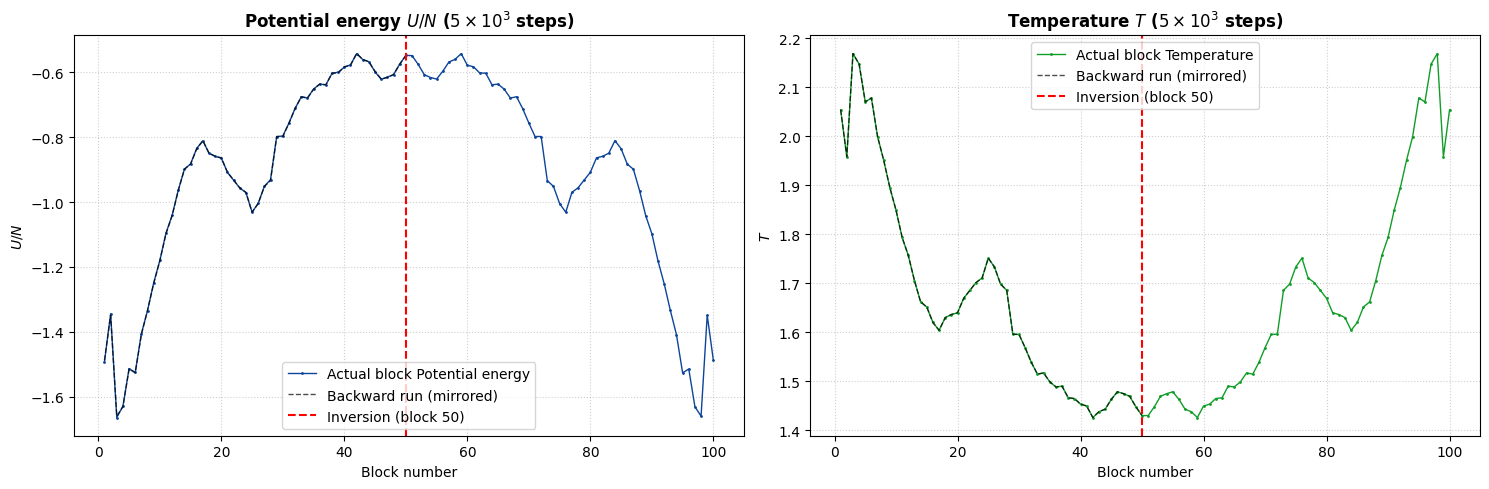

In [5]:
def plot_run(steps):
    folder = runs[steps]
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    for ax, (fname, ylabel, name, color) in zip(axes, props):
        block, y = np.loadtxt(f'{folder}/{fname}')[:, :2].T
        rev = len(block) // 2  # inversion point: half of the total blocks

        ax.plot(block, y, color=color, marker='o', ms=1, lw=1, label=f'Actual block {name}')
        ax.plot(block[:rev], y[-rev:][::-1], 'k--', lw=1, alpha=0.7, label='Backward run (mirrored)')
        ax.axvline(rev, color='red', ls='--', lw=1.5, label=f'Inversion (block {rev})')

        ax.set_title(f'{name} {ylabel} ({steps} steps)', fontsize=12, fontweight='bold')
        ax.set_xlabel('Block number')
        ax.set_ylabel(ylabel)
        ax.grid(True, ls=':', alpha=0.6)
        ax.legend(loc='best')

    plt.tight_layout()
    plt.show()

plot_run(r'$5\times 10^3$')

From the graph we can see that for a short trajectory the system exhibits a perfect mirror-like symmetry with respect to the inversion line, matching our expectation. It can also be seen that the system has not reached thermal equilibrium, as there is no plateau in the plotted quantities: the run is short enough that, as we said, the errors had no time to grow and change the trajectory.

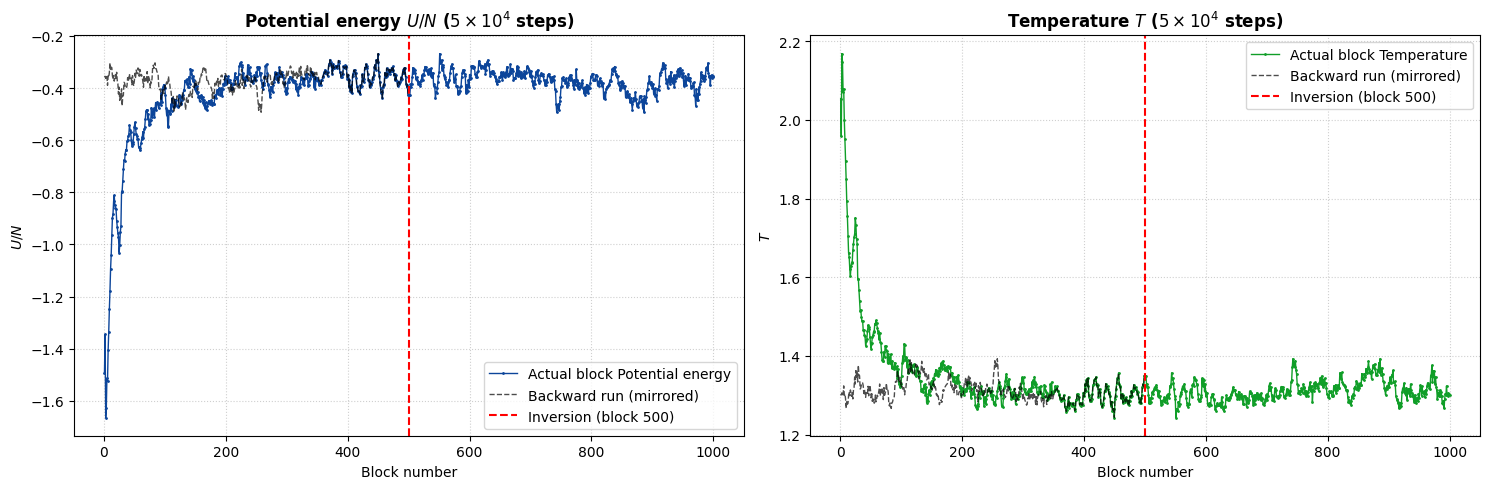

In [6]:
plot_run(r'$5\times 10^4$')

For the long trajectory the behaviour is different. In the forward run the potential energy and the temperature reach a plateau, so the system thermalizes. After the inversion the backward run follows the mirrored curve only for a limited number of blocks (about 100 blocks) and then separates from it: the round-off errors, amplified by the chaotic dynamics, have grown enough to change the trajectory. The system therefore stays at the equilibrium values and does not return to the initial low-entropy state, even though the dynamics is reversible in principle.

#### Conclusion
The two runs show the difference between microscopic reversibility and macroscopic irreversibility. The equations of motion, and the Verlet algorithm that integrates them, are symmetric under time reversal, so in principle the system can always go back to its low-entropy initial state. In practice this requires reversing all the velocities with infinite precision, but any tiny error is amplified exponentially by the chaotic dynamics, and the system ends up in the equilibrium macrostate. Irreversibility is therefore statistical, not a violation of the laws of motion and it is why we observe entropy increasing.